# 2 · Planning on the grid world

This notebook reproduces the planning half of the report's grid-world experiments:

* **Figure 1a and the table below it:** the optimal policy of one 7 × 8 world, found by value
  iteration and by policy iteration;
* **Figure 2:** how the cost of both algorithms grows from 9 to about 1,500 states;
* **Figure 3:** the optimal policy of a 39 × 39 world, and two corners of it that the report puzzles over.

Worlds are random, so in general only the *behaviour* can be reproduced, not the numbers. Two
worlds are exceptions. Those of Figures 1 and 3 were drawn in the report, and both have been
decoded from the drawings (see notebook 1), so for them the comparison is exact.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import mdplab as ml
from mdplab import plotting as mp
from mdplab import report
from mdplab.gridworld import ARROWS, GOAL, REPORT_FIG1A_POLICY
from mdplab.legacy import policy_iteration_2014, value_iteration_2014

mp.use_style()
pd.options.display.float_format = "{:,.3f}".format

## Figure 1a: the optimal policy of a 7 × 8 world

Value iteration here is the plain synchronous kind, stopped when no value changes by more than
$10^{-6}$ in a sweep. That tolerance is not stated in the report; notebook 4 infers it from the
elevator experiments, where it reproduces the published iteration counts exactly.

Value iteration and policy iteration agree with each other in **42 of 42** cells, and with the arrows drawn in the report in **42 of 42**.

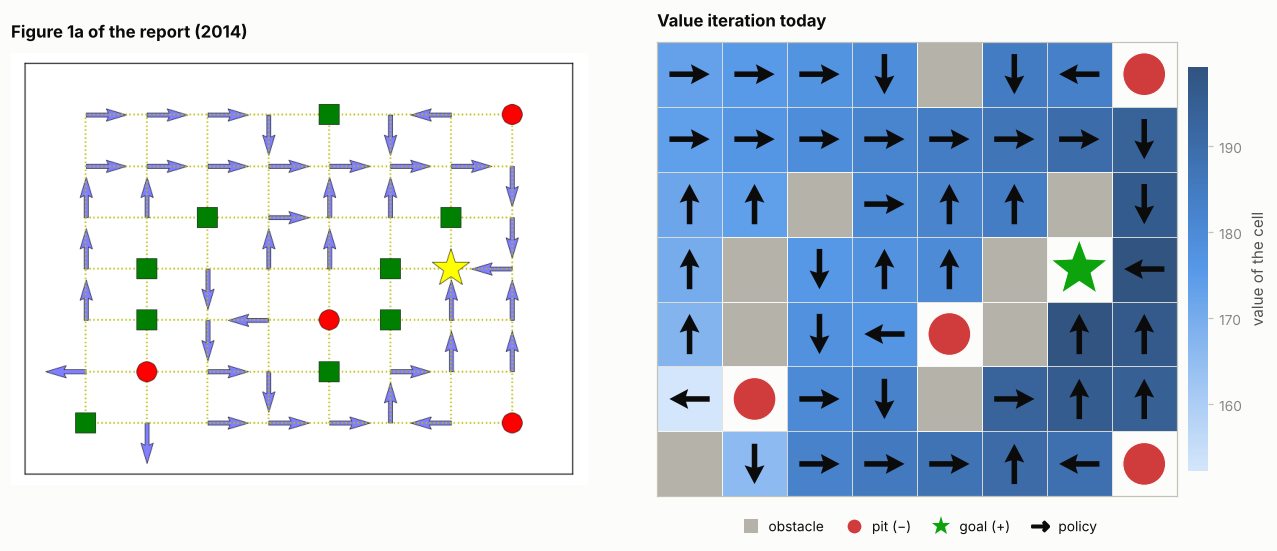

In [2]:
world = ml.GridWorld.report_figure1()
mdp = world.mdp
free = world.free

vi = ml.value_iteration(mdp, tol=1e-6)
pi = ml.policy_iteration(mdp)
drawn = world.policy_from_text(REPORT_FIG1A_POLICY)  # the arrows of Figure 1a, decoded from the image

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.9))
mp.show_original("fig1a", axes[0], title="Figure 1a of the report (2014)")
mp.plot_gridworld(world, vi.policy, values=vi.V, ax=axes[1], title="Value iteration today", value_label="value of the cell")
mp.savefig(fig, "02_figure1a")

display(Markdown(
    f"Value iteration and policy iteration agree with each other in "
    f"**{int((vi.policy == pi.policy)[free].sum())} of {int(free.sum())}** cells, and with the arrows "
    f"drawn in the report in **{int((vi.policy == drawn)[free].sum())} of {int(free.sum())}**."
))

The rebuilt model returns the 2014 policy arrow for arrow. The report's table for this world can
now be filled in again. "Expected reward" there is the undiscounted sum of rewards, averaged over
all starting cells and estimated by simulating 100 episodes from each. With the model in hand the
same quantity can be computed exactly, and the simulation repeated for comparison.

In [3]:
outcome = ml.absorption(mdp, vi.policy)
exact_reward = outcome.total_reward[free].mean()
sim = ml.monte_carlo(mdp, vi.policy, n_restarts=100, seed=0)

orders = {
    "top to bottom": np.flatnonzero(mdp.active),
    "bottom to top": np.array([world.state(r, c) for r in range(6, -1, -1) for c in range(8) if free[world.state(r, c)]]),
}
orders["top to bottom, reversed"] = orders["top to bottom"][::-1]
orders["bottom to top, reversed"] = orders["bottom to top"][::-1]
in_place = {name: ml.gauss_seidel_value_iteration(mdp, tol=1e-6, order=o).iterations for name, o in orders.items()}
pi_rounds = {ARROWS[a]: ml.policy_iteration(mdp, policy0=np.full(mdp.n_states, a)).iterations for a in range(4)}

then = report.TABLE_GRIDWORLD
table = pd.DataFrame(
    {
        "report (2014)": [then.loc["Value iteration", "iterations"], then.loc["Policy iteration", "iterations"], then.loc["Value iteration", "expected_reward"]],
        "today": [
            f"{vi.iterations} (in place: {min(in_place.values())} to {max(in_place.values())})",
            f"{min(pi_rounds.values())} to {max(pi_rounds.values())}, depending on the starting policy",
            f"{exact_reward:.3f} exact, {sim.total_reward.mean():.1f} simulated",
        ],
    },
    index=["value iteration, sweeps", "policy iteration, rounds", "expected reward"],
)
table

,report (2014),today
"value iteration, sweeps",152.000,159 (in place: 143 to 152)
"policy iteration, rounds",6.000,"6 to 9, depending on the starting policy"
expected reward,199.900,"199.905 exact, 199.9 simulated"


* **Expected reward** matches: 199.9.
* **Policy iteration** needs 6 rounds when started from "always left" and up to 9 from the other
  three uniform starting policies; the report says 6 and does not say where it started.
* **Value iteration** takes 159 synchronous sweeps against the report's 152. If instead each sweep
  updates the values in place, so that later cells already see the new values of earlier ones, the
  count falls to between 143 and 152 depending on the order of the sweep, and 152 is what sweeping
  the rows from the bottom up gives. The 2014 grid code was most likely an in-place loop; which
  order it used cannot be recovered.

### Why the policy looks the way it does

A pit costs 20,000 times as much as a move, so the optimal policy never accepts a slip into a pit
if a detour, however long, avoids it. From every one of the 42 cells it reaches the goal with
certainty:

In [4]:
p_goal = ml.hitting_probability(mdp, vi.policy, world.mask(GOAL))
steps = outcome.steps
waiting = [world.state(6, 1), world.state(5, 0)]
display(Markdown(
    f"* probability of ending at the goal: at least **{p_goal[free].min():.6f}** from any cell;\n"
    f"* expected number of moves: **{steps[free].mean():.1f}** on average, and "
    f"**{steps[waiting[0]]:.1f}** and **{steps[waiting[1]]:.1f}** from the two cells in the bottom-left corner."
))

* probability of ending at the goal: at least **1.000000** from any cell;
* expected number of moves: **10.5** on average, and **20.0** and **28.5** from the two cells in the bottom-left corner.

Those two cells are where the policy aims *at a wall*: straight down from the bottom row, and
left from the left edge. Notebook 1 showed why. Each sits beside a pit, any move along the pit
risks a slip into it, and bumping into the wall until a slip carries the agent sideways costs ten
moves at a cent apiece. The report calls this "taking the scenic route". It is the single most
important feature of these worlds for everything that follows: it is what the 2014 Q-learner
failed to learn (notebook 3), and it is what makes value iteration slow (notebook 6).

## Figure 2: cost against the number of states

The report solved worlds of 3 × 3, 3 × 4, 4 × 4, … up to 38 × 39 cells, averaging value iteration
over 20 random worlds of each size. The experiment is repeated below with fresh random worlds, and
plotted together with the numbers read off the report's figure.

In [5]:
sizes = sorted({(n, n) for n in range(3, 39)} | {(n, n + 1) for n in range(3, 39)}, key=lambda s: s[0] * s[1])
rng = np.random.default_rng(2014)
records = []
for rows, cols in sizes:
    for _ in range(20):
        w = ml.GridWorld.random(rows, cols, seed=rng)
        a = ml.value_iteration(w.mdp, tol=1e-6)
        b = ml.policy_iteration(w.mdp)
        records.append((rows * cols, a.iterations, b.iterations, a.seconds, b.seconds))
runs = pd.DataFrame(records, columns=["states", "vi_sweeps", "pi_rounds", "vi_seconds", "pi_seconds"])
mean = runs.groupby("states").mean()
then2 = report.figure2().set_index("states")

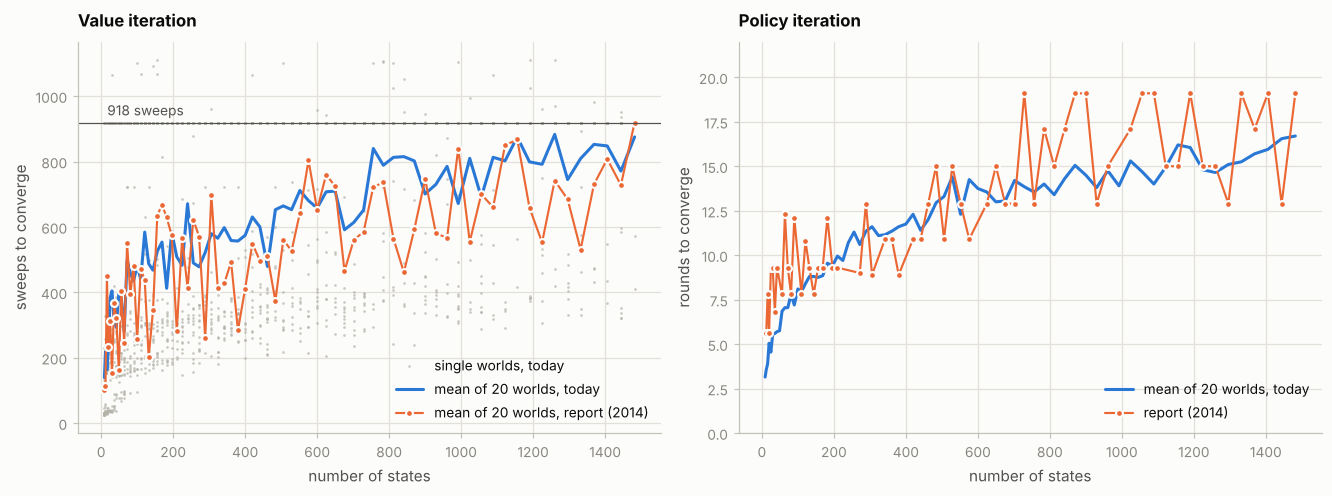

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
ax.plot(runs.states, runs.vi_sweeps, ".", color=mp.GREY, markersize=3.5, markeredgewidth=0, alpha=0.7, label="single worlds, today")
ax.plot(mean.index, mean.vi_sweeps, color=mp.SERIES[0], label="mean of 20 worlds, today")
ax.plot(then2.index, then2.vi_iterations, color=mp.SERIES[1], linewidth=1.4, marker="o", markersize=4.5, label="mean of 20 worlds, report (2014)")
ax.axhline(918, color=mp.INK_SECONDARY, linewidth=0.8)
ax.annotate("918 sweeps", (0, 918), xytext=(4, 5), textcoords="offset points", fontsize=9, color=mp.INK_SECONDARY)
ax.set(xlabel="number of states", ylabel="sweeps to converge", title="Value iteration")
ax.legend(loc="lower right")
ax = axes[1]
ax.plot(mean.index, mean.pi_rounds, color=mp.SERIES[0], label="mean of 20 worlds, today")
then_pi = then2.pi_iterations.dropna()  # a few markers could not be read off the figure
ax.plot(then_pi.index, then_pi, color=mp.SERIES[1], linewidth=1.4, marker="o", markersize=4.5, label="report (2014)")
ax.set(xlabel="number of states", ylabel="rounds to converge", title="Policy iteration", ylim=(0, 22))
ax.legend(loc="lower right")
mp.savefig(fig, "02_figure2_iterations");

Both of the report's observations reappear. Policy iteration needs an order of magnitude fewer
iterations than value iteration, a number that creeps up only slowly with the size of the world.
And value iteration is, in the report's word, volatile: even averaged over 20 worlds, the curve
jumps around by hundreds of sweeps, in 2014 and today alike.

The grey dots show where the volatility comes from. The sweep count of a single world is not
spread around its mean at all. A large group of worlds takes 918 sweeps, whatever their size (a
handful take a little more), and the rest are scattered far below. An average of 20 is then mostly
a count of how many of the 20 landed on the line:

In [7]:
ceiling = runs.assign(on_line=runs.vi_sweeps >= 918).groupby("states").on_line.mean()
bins = pd.cut(ceiling.index, [0, 50, 200, 500, 1000, 1500])
summary = pd.DataFrame({
    "share of worlds needing 918 sweeps or more": ceiling.groupby(bins, observed=True).mean(),
    "mean sweeps of the others": runs[runs.vi_sweeps < 918].groupby(pd.cut(runs[runs.vi_sweeps < 918].states, [0, 50, 200, 500, 1000, 1500]), observed=True).vi_sweeps.mean(),
})
summary.index.name = "states"
summary

,share of worlds needing 918 sweeps or more,mean sweeps of the others
states,,
"(0, 50]",0.183,139.061
"(50, 200]",0.314,261.089
"(200, 500]",0.381,337.152
"(500, 1000]",0.592,411.065
"(1000, 1500]",0.768,446.108


Where the number 918 comes from, and what decides whether a world lands on it, is the subject of
notebook 6. In short: it is the number of sweeps needed by a world that contains a cell in which
the best the agent can do is to bump into a wall for ever, and large random worlds almost always
contain one.

### Seconds, then and now

The report's second pair of plots shows running times, and its conclusion was that on the grid
world policy iteration, despite needing far fewer iterations, was slower than value iteration.

At 1482 states the report needed about **1,927 s** for value iteration and **4,953 s** for policy iteration. The same solves now take **0.11 s** and **0.04 s**.

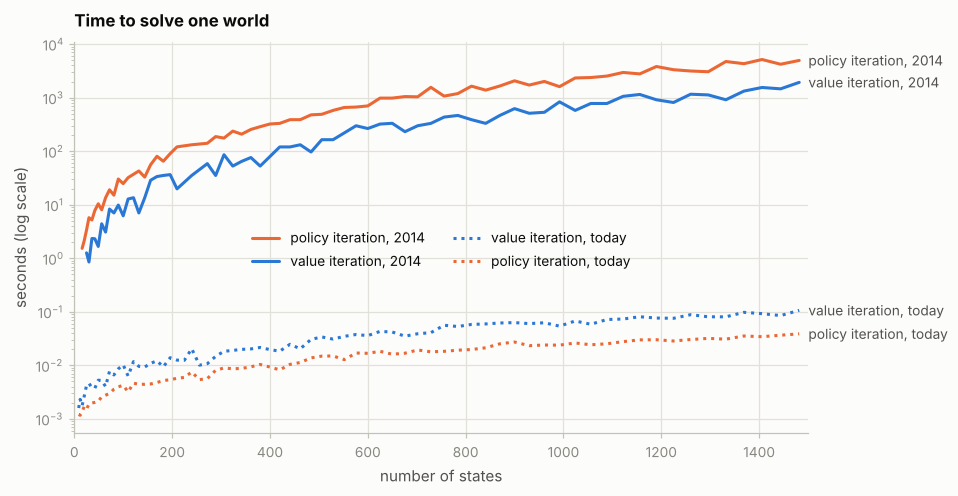

In [8]:
fig, ax = plt.subplots(figsize=(8.6, 4.4))
lines = [
    (then2.pi_seconds.dropna(), mp.SERIES[1], "-", "policy iteration, 2014"),
    (then2.vi_seconds.dropna(), mp.SERIES[0], "-", "value iteration, 2014"),
    (mean.vi_seconds, mp.SERIES[0], (0, (1, 1.6)), "value iteration, today"),
    (mean.pi_seconds, mp.SERIES[1], (0, (1, 1.6)), "policy iteration, today"),
]
for series, colour, style, label in lines:
    ax.plot(series.index, series, color=colour, linestyle=style, label=label)
    mp.end_label(ax, series.index[-1], series.iloc[-1], label)
ax.set(yscale="log", xlabel="number of states", ylabel="seconds (log scale)", title="Time to solve one world", xlim=(0, 1500))
ax.legend(ncol=2, loc="center", bbox_to_anchor=(0.5, 0.47))
mp.savefig(fig, "02_figure2_seconds")

big = mean.index.max()
display(Markdown(
    f"At {big} states the report needed about **{then2.vi_seconds[big]:,.0f} s** for value iteration and "
    f"**{then2.pi_seconds[big]:,.0f} s** for policy iteration. The same solves now take "
    f"**{mean.vi_seconds[big]:.2f} s** and **{mean.pi_seconds[big]:.2f} s**."
))

Two things changed, and neither is the hardware alone. The 2014 code looped over states and
actions in Python; here a sweep is one sparse matrix product. And policy iteration here evaluates
each policy by solving a linear system instead of sweeping to convergence. With those two changes
the ranking flips: policy iteration is now the faster of the two.

So the report's finding that policy iteration is slower on the grid world was a fact about one way
of implementing it. That does not make the finding uninteresting. Written as plain textbook loops,
the algorithms still behave as the report describes, here on the 7 × 8 world:

In [9]:
loop_vi = value_iteration_2014(mdp, loops=True)
loop_pi = policy_iteration_2014(mdp, loops=True, policy0=np.full(mdp.n_states, 3))
pd.DataFrame(
    {
        "report (2014), seconds": [then.loc["Value iteration", "seconds"], then.loc["Policy iteration", "seconds"]],
        "textbook loops today, seconds": [loop_vi.seconds, loop_pi.seconds],
        "this package, seconds": [vi.seconds, pi.seconds],
    },
    index=["value iteration", "policy iteration"],
)

,"report (2014), seconds","textbook loops today, seconds","this package, seconds"
value iteration,1.780,0.026,0.002
policy iteration,11.420,0.208,0.004


With loops, policy iteration is again several times slower than value iteration, as in 2014.
Notebook 6 explains the ratio by counting the work both algorithms do, and shows why the same
count comes out the other way round on the elevator.

## Figure 3: a 39 × 39 world

The report's largest drawing shows the optimal policy of a random 39 × 39 world, which it likens
to a vector field "complete with a source and some sinks". The world has 1,521 cells; decoding it
from the image gives 147 obstacles, 135 pits and 1,238 free cells, each with an arrow.

Of the 1,238 arrows in the report's figure, **1,234** are identical to today's and **all 1,238** are optimal moves in the rebuilt model (the 4 that differ are exact ties). Value iteration takes **918** sweeps on this world.

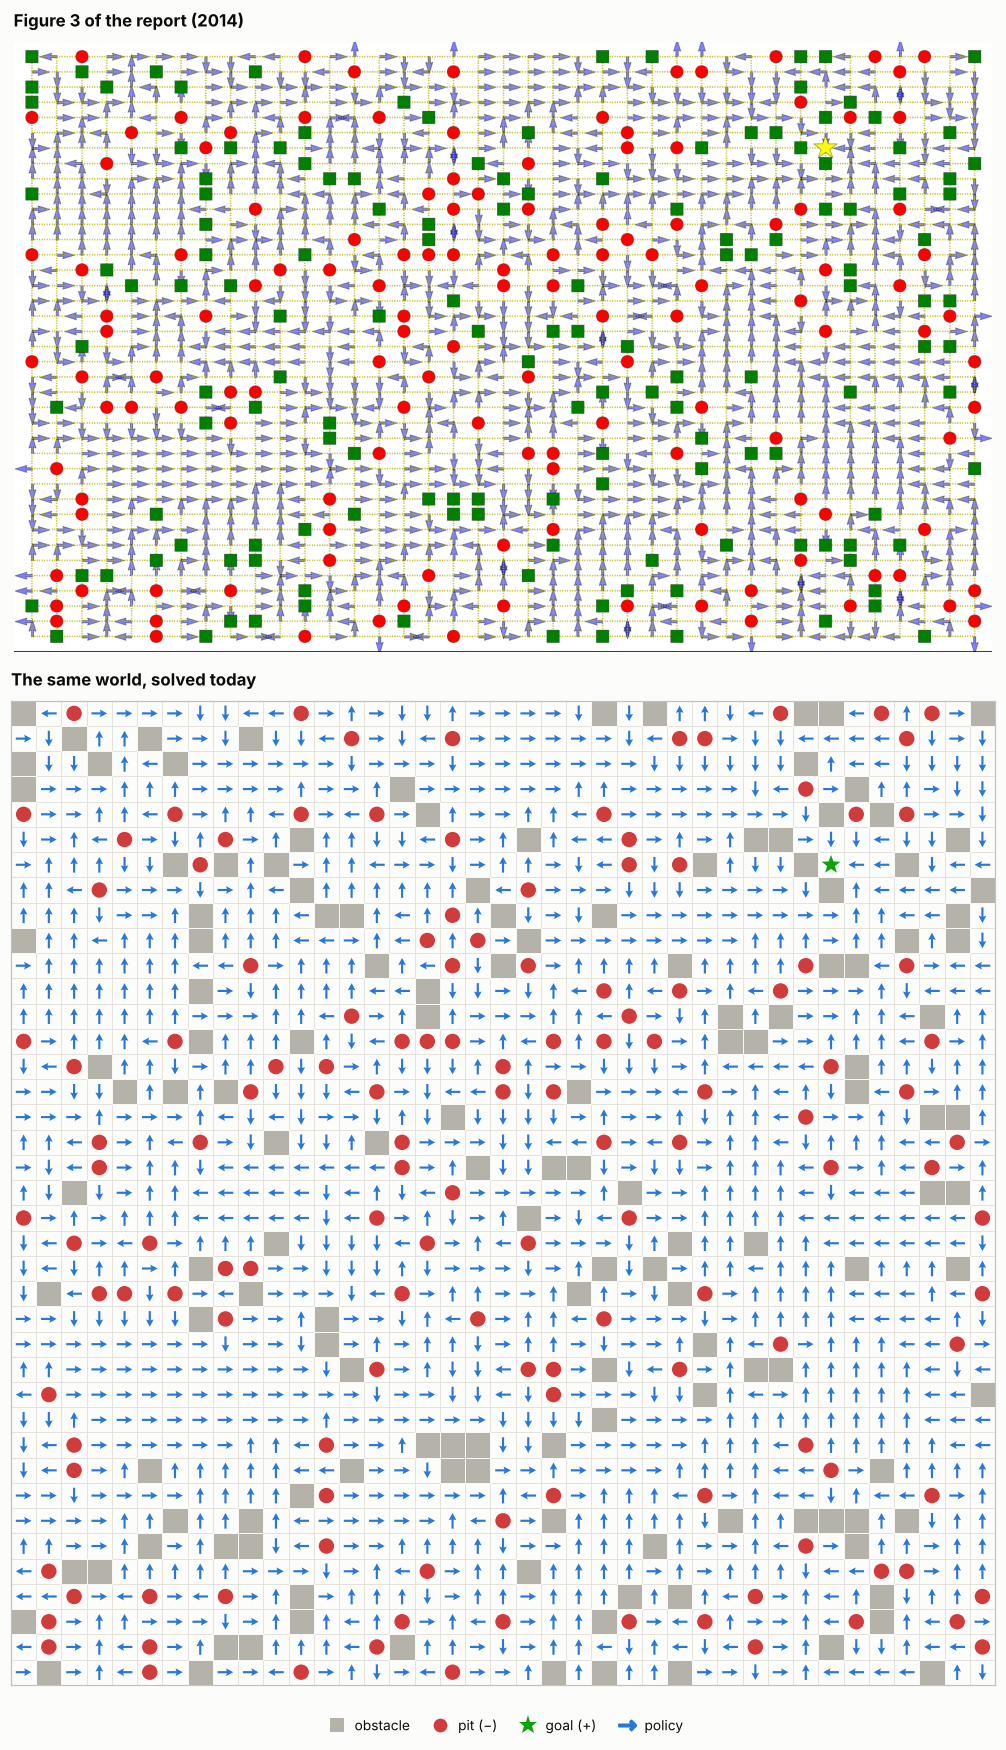

In [10]:
world3 = report.figure3_gridworld()
mdp3 = world3.mdp
free3 = world3.free
drawn3 = report.figure3_policy()
vi3 = ml.value_iteration(mdp3, tol=1e-6)
optimal3 = ml.optimal_actions(mdp3, vi3.V, atol=1e-4)

fig, axes = plt.subplots(2, 1, figsize=(9.6, 15.8), height_ratios=[0.62, 1])
mp.show_original("fig3", axes[0], title="Figure 3 of the report (2014)")
mp.plot_gridworld(world3, vi3.policy, ax=axes[1], title="The same world, solved today")
mp.savefig(fig, "02_figure3")

same = int((drawn3 == vi3.policy)[free3].sum())
good = int(optimal3[np.arange(mdp3.n_states), drawn3][free3].sum())
display(Markdown(
    f"Of the {int(free3.sum()):,} arrows in the report's figure, **{same:,}** are identical to today's and "
    f"**all {good:,}** are optimal moves in the rebuilt model (the {good - same} that differ are exact ties). "
    f"Value iteration takes **{vi3.iterations}** sweeps on this world."
))

The decoder knows nothing about the model; it only looks at the picture. That every one of 1,238
arrows drawn in 2014 comes out optimal is strong evidence that the rebuilt grid world, its
rewards, its slip probabilities and its discount factor are the ones the report used.

### The two corners the report puzzles over

The report points at two spots in this figure: one "in the lower left corner" and one "just above
the lower right corner".

In [11]:
corners = {"lower left": [(37, 0), (38, 0)], "above the lower right": [(36, 38)]}
Q3 = mdp3.q_values(vi3.V)
never_ends = ~ml.absorption(mdp3, vi3.policy).proper
rows_out = []
for where, cells in corners.items():
    for r, c in cells:
        s = world3.state(r, c)
        rows_out.append({
            "corner": where, "cell (row, column)": (r, c), "optimal move": ARROWS[vi3.policy[s]], "value": vi3.V[s],
            **{f"value of {ARROWS[a]}": Q3[s, a] for a in range(4)}, "episode may never end": bool(never_ends[s]),
        })
pd.DataFrame(rows_out).set_index(["corner", "cell (row, column)"])

optimal move    value  value of ↑  \
corner                cell (row, column)                                     
lower left            (37, 0)                       ←   -1.000     -20.900   
                      (38, 0)                       →   -1.000      -1.000   
above the lower right (36, 38)                      → -192.346    -199.043   

                                          value of →  value of ↓  value of ←  \
corner                cell (row, column)                                       
lower left            (37, 0)               -160.200     -20.900      -1.000   
                      (38, 0)                 -1.000      -1.000      -1.000   
above the lower right (36, 38)              -192.346    -199.043    -200.000   

                                          episode may never end  
corner                cell (row, column)                         
lower left            (37, 0)                              True  
                      (38, 0)                              True  
above the lower right (36, 38)                            False

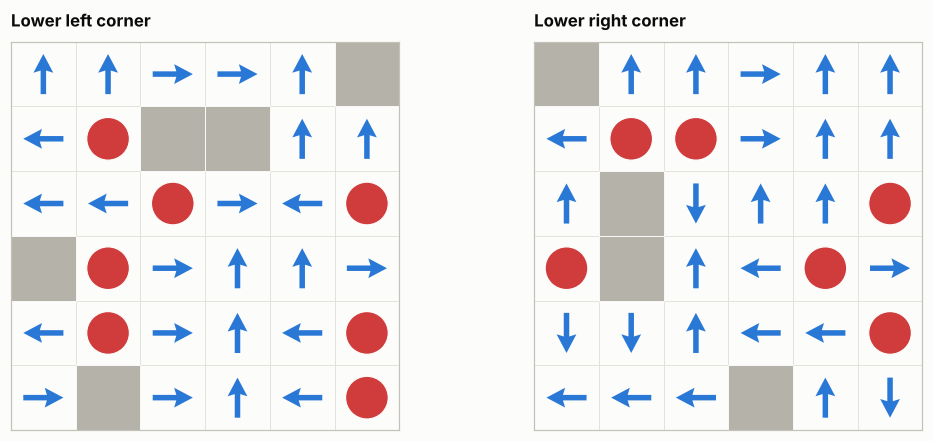

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.9))
for ax, (r0, c0, title) in zip(axes, [(33, 0, "Lower left corner"), (33, 33, "Lower right corner")]):
    mp.plot_gridworld(world3, vi3.policy, ax=ax, title=title, legend=False)
    ax.set_xlim(c0 - 0.5, c0 + 5.5)
    ax.set_ylim(38.5, r0 - 0.5)
mp.savefig(fig, "02_figure3_corners");

**Lower left.** The two cells in the corner are walled in by an obstacle and a pit. The goal cannot
be reached, and the only way out is into the pit. The policy instead pushes against the wall for
ever. The report works out why: with discounting, an endless stream of 0.01 costs adds up to only
$0.01 / (1 - 0.99) = 1$, far better than the 200 lost in the pit. The table confirms a value of
exactly −1.

**Above the lower right.** This cell has pits above, below and to its left and the edge of the
grid to its right. Here there is no safe move: even bumping into the edge slips into a pit one
time in five. The fall is inevitable, and the report finds the policy's choice to bump, and so to
pay for extra moves on the way to the same −200, "less than optimal". It is optimal, and the
reason is again the discount factor. A penalty of 200 one step later is worth
$0.99 \times 200 = 198$ today, so each step of delay gains 2 and costs 0.01. Waiting has value

In [13]:
wait = (0.2 * -200 + 0.8 * -0.01) / (1 - 0.99 * 0.8)
display(Markdown(
    rf"$$\frac{{0.2 \times (-200) + 0.8 \times (-0.01)}}{{1 - 0.99 \times 0.8}} = {wait:.2f},$$" "\n\n"
    f"which is what value iteration found for that cell, against about −199 for stepping towards a pit. "
    f"Without discounting the comparison reverses, and the report's intuition would be right; notebook 7 follows that up."
))

$$\frac{0.2 \times (-200) + 0.8 \times (-0.01)}{1 - 0.99 \times 0.8} = -192.35,$$

which is what value iteration found for that cell, against about −199 for stepping towards a pit. Without discounting the comparison reverses, and the report's intuition would be right; notebook 7 follows that up.

## What was reproduced

| Report | Today |
|---|---|
| Figure 1a, optimal policy of the 7 × 8 world | identical in all 42 cells |
| Expected reward 199.9 | 199.905 exact |
| Value iteration: 152 sweeps | 159 synchronous; 143 to 152 in place |
| Policy iteration: 6 rounds | 6 to 9, depending on the starting policy |
| Figure 2: policy iteration needs far fewer iterations; value iteration is volatile | same, with the cause of the volatility visible |
| Figure 2: policy iteration is slower in seconds | true for loop-style code, reversed for matrix code |
| Figure 3, optimal policy of the 39 × 39 world | all 1,238 drawn arrows are optimal |

Next: [3 · Q-learning on the grid world](03_gridworld_q_learning.ipynb).